# Benchmark v1: thêm nhóm kết quả theo ảnh nguyên

Phiên bản trước (v0, `benchmark_models.ipynb`, `reports/`) có **22/47 ảnh test trượt ngay từ YOLO**: 14 ảnh YOLO gán sai lớp cho món cần tìm, 8 ảnh không có hộp nào phủ món đó. Trong 25 ảnh YOLO tìm đúng món, B0 trúng 20 ảnh.

**Phát hiện làm đổi kế hoạch.** Với `conf = 0.5`, YOLO luôn trả về ít nhất một hộp trên cả 75/75 ảnh benchmark. Nhóm "không phát hiện" thật ra là có hộp nhưng các hộp không phủ món cần tìm. Vì vậy cách dự phòng ban đầu, "YOLO không thấy gì thì tìm bằng ảnh nguyên", **không bao giờ được kích hoạt**. Cách này được giữ lại dưới tên F1 để chứng minh điều đó bằng số đo.

| Cấu hình | Định nghĩa |
|---|---|
| `F1_B0_nodet` | B0; nếu YOLO không trả hộp nào thì tìm bằng ảnh nguyên (đường A0) |
| `F2_B0_whole` | Các nhóm theo món của B0, **cộng thêm một nhóm "ảnh nguyên"** (xếp hạng cosine như A0) |
| `F2_C2_whole` | Các nhóm C2, cộng cùng nhóm ảnh nguyên (so model embedding thuần) |

- **Nhóm người dùng chọn** (cùng giả định như v0): nếu có nhóm YOLO đúng lớp và IoU ≥ 0,5 với món đã gán nhãn thì dùng nhóm đó, nếu không thì dùng nhóm ảnh nguyên.
- Nhóm ảnh nguyên qua cùng quyết định production (`apply_match_threshold`, 0,70 / 0,60) như các nhóm khác, nên vẫn đo được false acceptance trên các ảnh `no_match`.

**Quy trình:**
1. Ghép kết quả trên validation, ghi `evaluation_new/locked_v1.json` gồm định nghĩa, luật chọn và số validation.
2. Sau đó mới ghép tập test. Test từ chối chạy nếu định nghĩa hoặc kết quả validation v0 đã đổi.

**Giới hạn:** ý tưởng dự phòng xuất phát từ phân tích lỗi trên tập test của v0, nên số test v1 chỉ là xác nhận, không hoàn toàn "mù".

Các cấu hình dự phòng được ghép từ kết quả v0 đã lưu của từng phần (B0 hoặc C2, và A0). Mỗi phần chạy độc lập và tất định, nên kết quả giống hệt chạy pipeline ghép. Độ trễ cộng thêm thời gian nhúng và truy xuất ảnh nguyên.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "evaluation_new").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
REPORTS = ROOT / "reports" / "v1"
REPORTS.mkdir(parents=True, exist_ok=True)

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

## 1. Ghép kết quả: validation → khóa → test

Cần kết quả v0 trong `evaluation_new/results/` (chạy `benchmark_models.ipynb` trước). Khóa đã có thì không ghi lại.

In [2]:
from evaluation_new.benchmark_v1 import LOCK, V1_RESULTS, run_test, run_validation

if not LOCK.exists():
    run_validation()
run_test()
lock = json.loads(LOCK.read_text(encoding="utf-8"))
print("Khóa lúc:", lock["locked_at"])
print("Luật chọn:", lock["adoption_rule"])
print("Cấu hình chính đã khóa:", lock["adopted_main_config"])
display(pd.DataFrame(lock["validation"]["fashionclip"]).T)
print("Kiểm tra trên validation:", lock["validation"]["checks"])

/home/nguyen-thanh-dat/miniconda3/envs/fvs-bench/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


clip_b16 {'F1_B0_nodet': 0, 'F2_B0_whole': 25, 'F2_C2_whole': 25}


dinov2_base {'F2_C2_whole': 25}


fashionclip {'F1_B0_nodet': 0, 'F2_B0_whole': 25, 'F2_C2_whole': 25}


fashionclip_stored {'F1_B0_nodet': 0, 'F2_B0_whole': 25, 'F2_C2_whole': 25}


laion_b32 {'F1_B0_nodet': 0, 'F2_B0_whole': 25, 'F2_C2_whole': 25}


marqo_fashionclip {'F1_B0_nodet': 0, 'F2_B0_whole': 25, 'F2_C2_whole': 25}


marqo_fashionsiglip {'F1_B0_nodet': 0, 'F2_B0_whole': 25, 'F2_C2_whole': 25}


siglip_b16 {'F1_B0_nodet': 0, 'F2_B0_whole': 25, 'F2_C2_whole': 25}
Cấu hình chính (đã khóa): F2_B0_whole
Khóa lúc: 2026-11-24T15:38:21.856791+00:00
Luật chọn: F2_B0_whole replaces B0_current as the main configuration if, on validation for FashionCLIP (the production model; thresholds are tuned for it): HitRate@5 gains >= 1 query, MRR@5 does not drop, and false acceptance on no_match queries does not increase. Test is then reported as is.
Cấu hình chính đã khóa: F2_B0_whole


,hit_at_5,mrr_at_5,false_acceptance
B0_current,11/22,0.308,0/1
F1_B0_nodet,11/22,0.308,0/1
F2_B0_whole,14/22,0.384,0/1
F2_C2_whole,13/22,0.394,1/1


Kiểm tra trên validation: {'hit_gain_queries': 3, 'mrr_delta': 0.07575757575757569, 'false_acceptance_delta': 0}


## 2. Tính điểm

In [3]:
from evaluation_new import plots
from evaluation_new.run_models import STORED
from evaluation_new.scoring import class_breakdown, collect, paired_vs_reference, write_tables

summary, per_query, failure_counts = collect(results=V1_RESULTS)
paired = paired_vs_reference(per_query)
write_tables(REPORTS, summary, per_query, failure_counts, paired)
usage = {}
for path in sorted(V1_RESULTS.glob("*/*/results.json")):
    usage[(path.parent.parent.name, path.parent.name)] = json.loads(path.read_text(encoding="utf-8"))["fallback_usage"]
display(pd.DataFrame(usage).T.rename_axis(["model", "split"]))

F1_B0_nodet  F2_B0_whole  F2_C2_whole
model               split                                            
clip_b16            test                0.0         25.0         25.0
                    validation          0.0          6.0          6.0
dinov2_base         test                NaN          NaN         25.0
                    validation          NaN          NaN          6.0
fashionclip         test                0.0         25.0         25.0
                    validation          0.0          6.0          6.0
fashionclip_stored  test                0.0         25.0         25.0
                    validation          0.0          6.0          6.0
laion_b32           test                0.0         25.0         25.0
                    validation          0.0          6.0          6.0
marqo_fashionclip   test                0.0         25.0         25.0
                    validation          0.0          6.0          6.0
marqo_fashionsiglip test                0.0         25.0         25.0
                    validation          0.0          6.0          6.0
siglip_b16          test                0.0         25.0         25.0
                    validation          0.0          6.0          6.0

### 2.1 Số ảnh dùng nhóm ảnh nguyên

F1 = 0 ở mọi model, đúng như phát hiện ở trên. F2 dùng nhóm ảnh nguyên ở mọi ảnh mà YOLO không có nhóm khớp món cần tìm: 25/52 ảnh test và 6/23 ảnh validation, gồm cả ảnh `no_match`.

## 3. So B0 với F2 trên tập test

In [4]:
CONFIGS = ["C2_embedding_only", "F2_C2_whole", "B0_current", "F1_B0_nodet", "F2_B0_whole"]
cols = ["hit_at_5_n", "has_match", "hit_at_5", "mrr_at_5", "judged_hit_at_5", "unjudged_at_5",
        "false_acceptance_n", "no_match", "total_ms_mean"]

test_hits = summary[(summary["split"] == "test") & (summary["model"] != STORED)].pivot_table(
    index="label", columns="config", values="hit_at_5_n")[CONFIGS]
display(test_hits)
main = summary[(summary["split"] == "test") & summary["config"].isin(["B0_current", "F2_B0_whole"])
               & (summary["model"] != STORED)][["label", "config", *cols]]
display(main)

config,C2_embedding_only,F2_C2_whole,B0_current,F1_B0_nodet,F2_B0_whole
label,,,,,
DINOv2 ViT-B/14,10.0,15.0,NaN,NaN,NaN
FashionCLIP (hiện tại),17.0,23.0,20.0,20.0,26.0
LAION CLIP ViT-B/32,17.0,23.0,17.0,17.0,23.0
Marqo-FashionCLIP,19.0,25.0,20.0,20.0,26.0
Marqo-FashionSigLIP,22.0,32.0,20.0,20.0,30.0
OpenAI CLIP ViT-B/16,8.0,10.0,15.0,15.0,17.0
SigLIP ViT-B/16,16.0,24.0,19.0,19.0,27.0


,label,config,hit_at_5_n,has_match,hit_at_5,mrr_at_5,judged_hit_at_5,unjudged_at_5,false_acceptance_n,no_match,total_ms_mean
9,FashionCLIP (hiện tại),B0_current,20,47,0.426,0.360,0.426,0,0,4,722.765
12,FashionCLIP (hiện tại),F2_B0_whole,26,47,0.553,0.438,0.553,0,0,4,750.156
16,Marqo-FashionCLIP,B0_current,20,47,0.426,0.370,0.447,29,0,4,1201.111
19,Marqo-FashionCLIP,F2_B0_whole,26,47,0.553,0.442,0.574,77,0,4,1259.551
23,OpenAI CLIP ViT-B/16,B0_current,15,47,0.319,0.233,0.340,59,0,4,969.085
26,OpenAI CLIP ViT-B/16,F2_B0_whole,17,47,0.362,0.265,0.426,139,0,4,1029.781
30,LAION CLIP ViT-B/32,B0_current,17,47,0.362,0.319,0.383,15,0,4,692.098
33,LAION CLIP ViT-B/32,F2_B0_whole,23,47,0.489,0.392,0.553,36,0,4,718.824
37,Marqo-FashionSigLIP,B0_current,20,47,0.426,0.358,0.426,35,1,4,1462.784
40,Marqo-FashionSigLIP,F2_B0_whole,30,47,0.638,0.485,0.660,108,2,4,1524.357


## 4. Bảng tổng hợp test

In [5]:
test_table = plots.summary_table(summary, "test")
display(test_table)
(REPORTS / "summary_test.md").write_text(plots.to_markdown(test_table), encoding="utf-8")

,config,model_label,dimension,hit_at_5,mrr_at_5,precision_at_5,joint_at_5,candidate_hit_at_100,judged_hit_at_5,judged_mrr_at_5,unjudged_at_5,target_recall,embed_ms_mean
0,A0_whole_image,FashionCLIP (vector gốc),512,0.340,0.214,0.111,0.431,0.851,0.340,0.214,0,NaN,27.384
1,A0_whole_image,FashionCLIP (hiện tại),512,0.340,0.214,0.111,0.431,0.851,0.340,0.214,0,NaN,25.917
2,A0_whole_image,Marqo-FashionCLIP,512,0.319,0.217,0.115,0.353,0.915,0.340,0.242,113,NaN,57.012
3,A0_whole_image,OpenAI CLIP ViT-B/16,512,0.170,0.129,0.064,0.255,0.745,0.277,0.191,170,NaN,59.689
4,A0_whole_image,LAION CLIP ViT-B/32,512,0.340,0.202,0.102,0.373,0.830,0.404,0.241,57,NaN,25.286
5,A0_whole_image,Marqo-FashionSigLIP,768,0.511,0.312,0.166,0.510,0.851,0.574,0.424,140,NaN,59.415
6,A0_whole_image,SigLIP ViT-B/16,768,0.404,0.215,0.132,0.373,0.872,0.468,0.302,144,NaN,60.747
7,A0_whole_image,DINOv2 ViT-B/14,768,0.213,0.134,0.055,0.255,0.681,0.340,0.289,194,NaN,92.670
8,C2_embedding_only,FashionCLIP (vector gốc),512,0.362,0.277,0.187,0.392,0.511,0.362,0.277,0,0.519,295.573
9,C2_embedding_only,FashionCLIP (hiện tại),512,0.362,0.277,0.187,0.392,0.511,0.362,0.277,0,0.519,277.095


6669

## 5. Biểu đồ (lưu vào `reports/v1/`)

**08_fallback_gain_test.png**

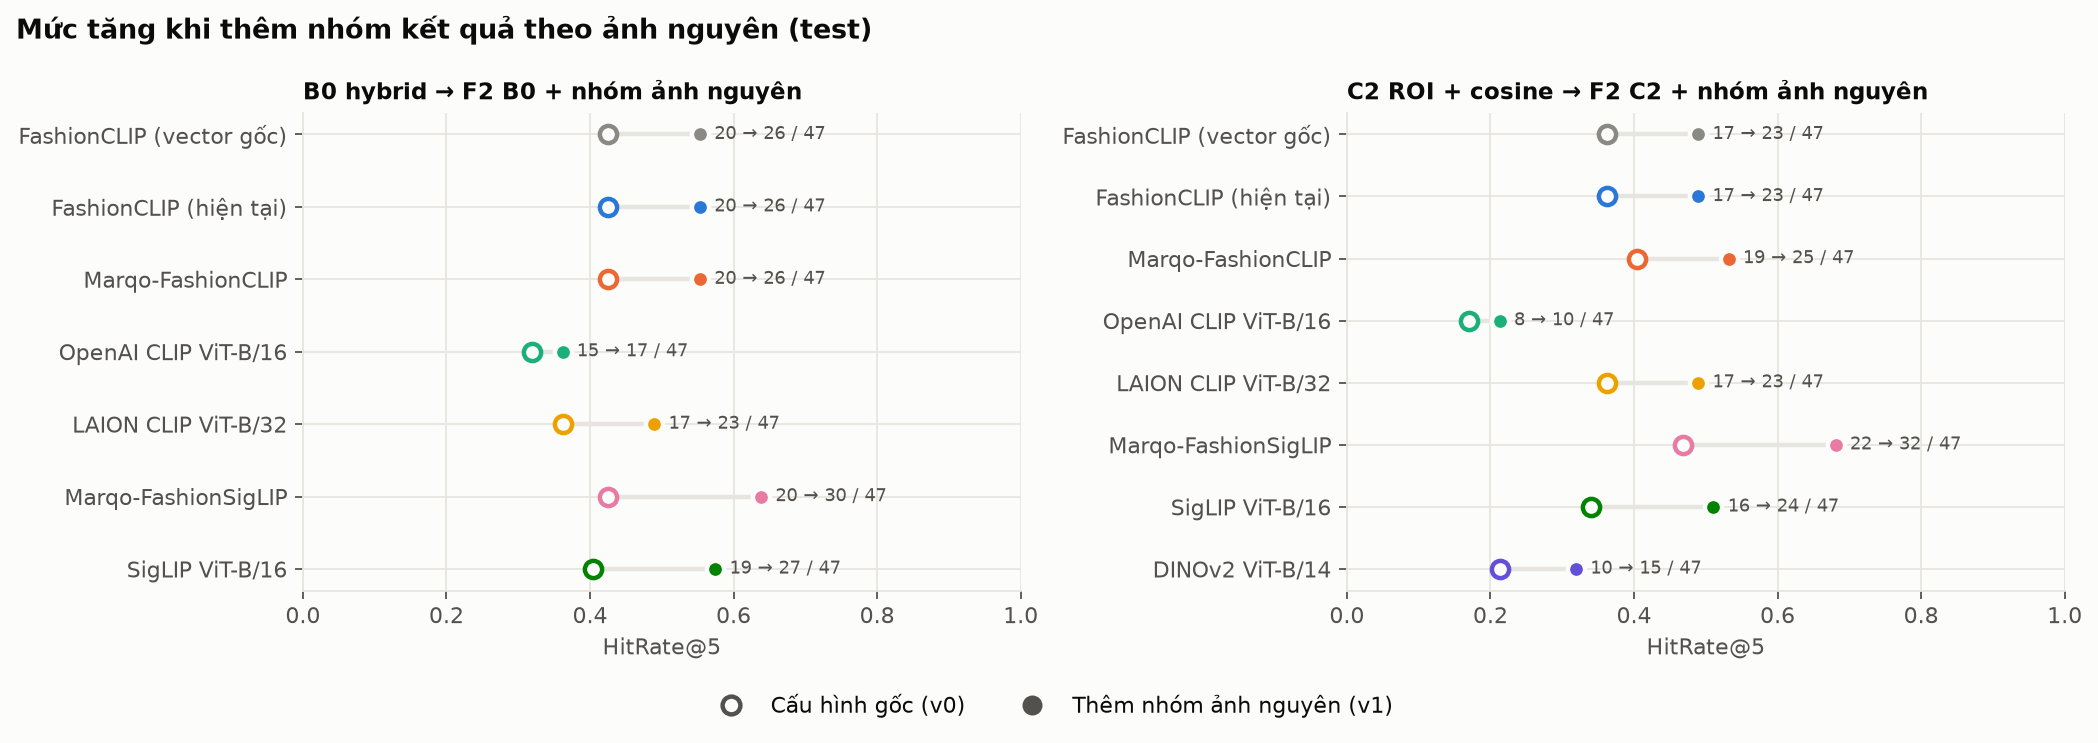

**08_fallback_gain_validation.png**

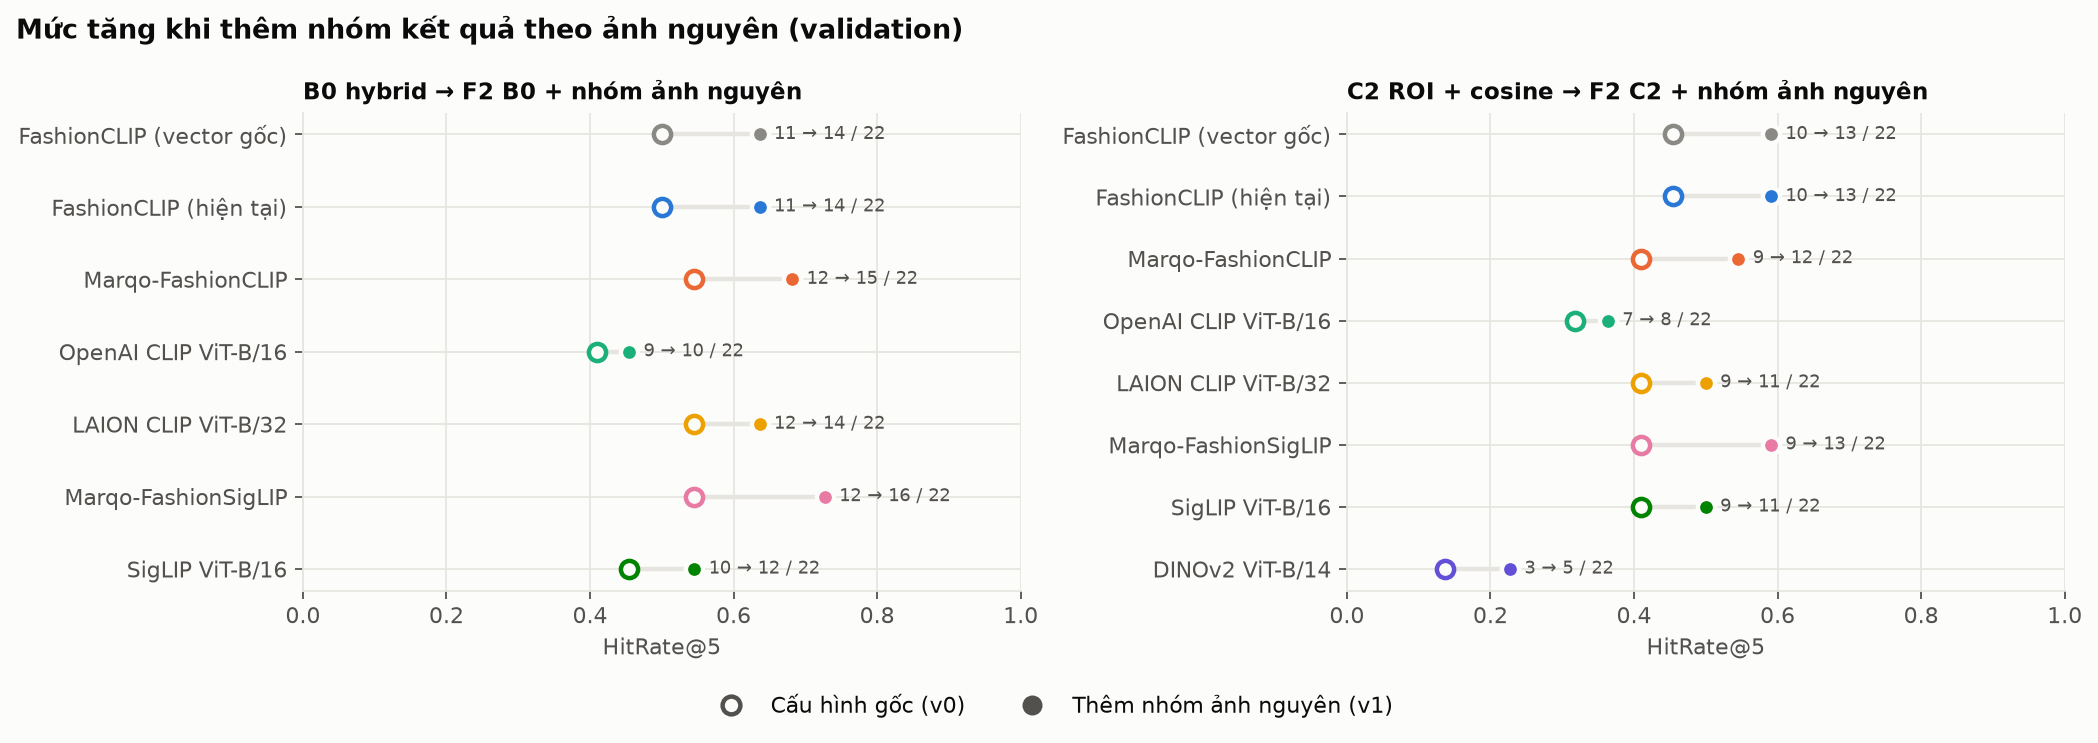

**01_hitrate_mrr_test.png**

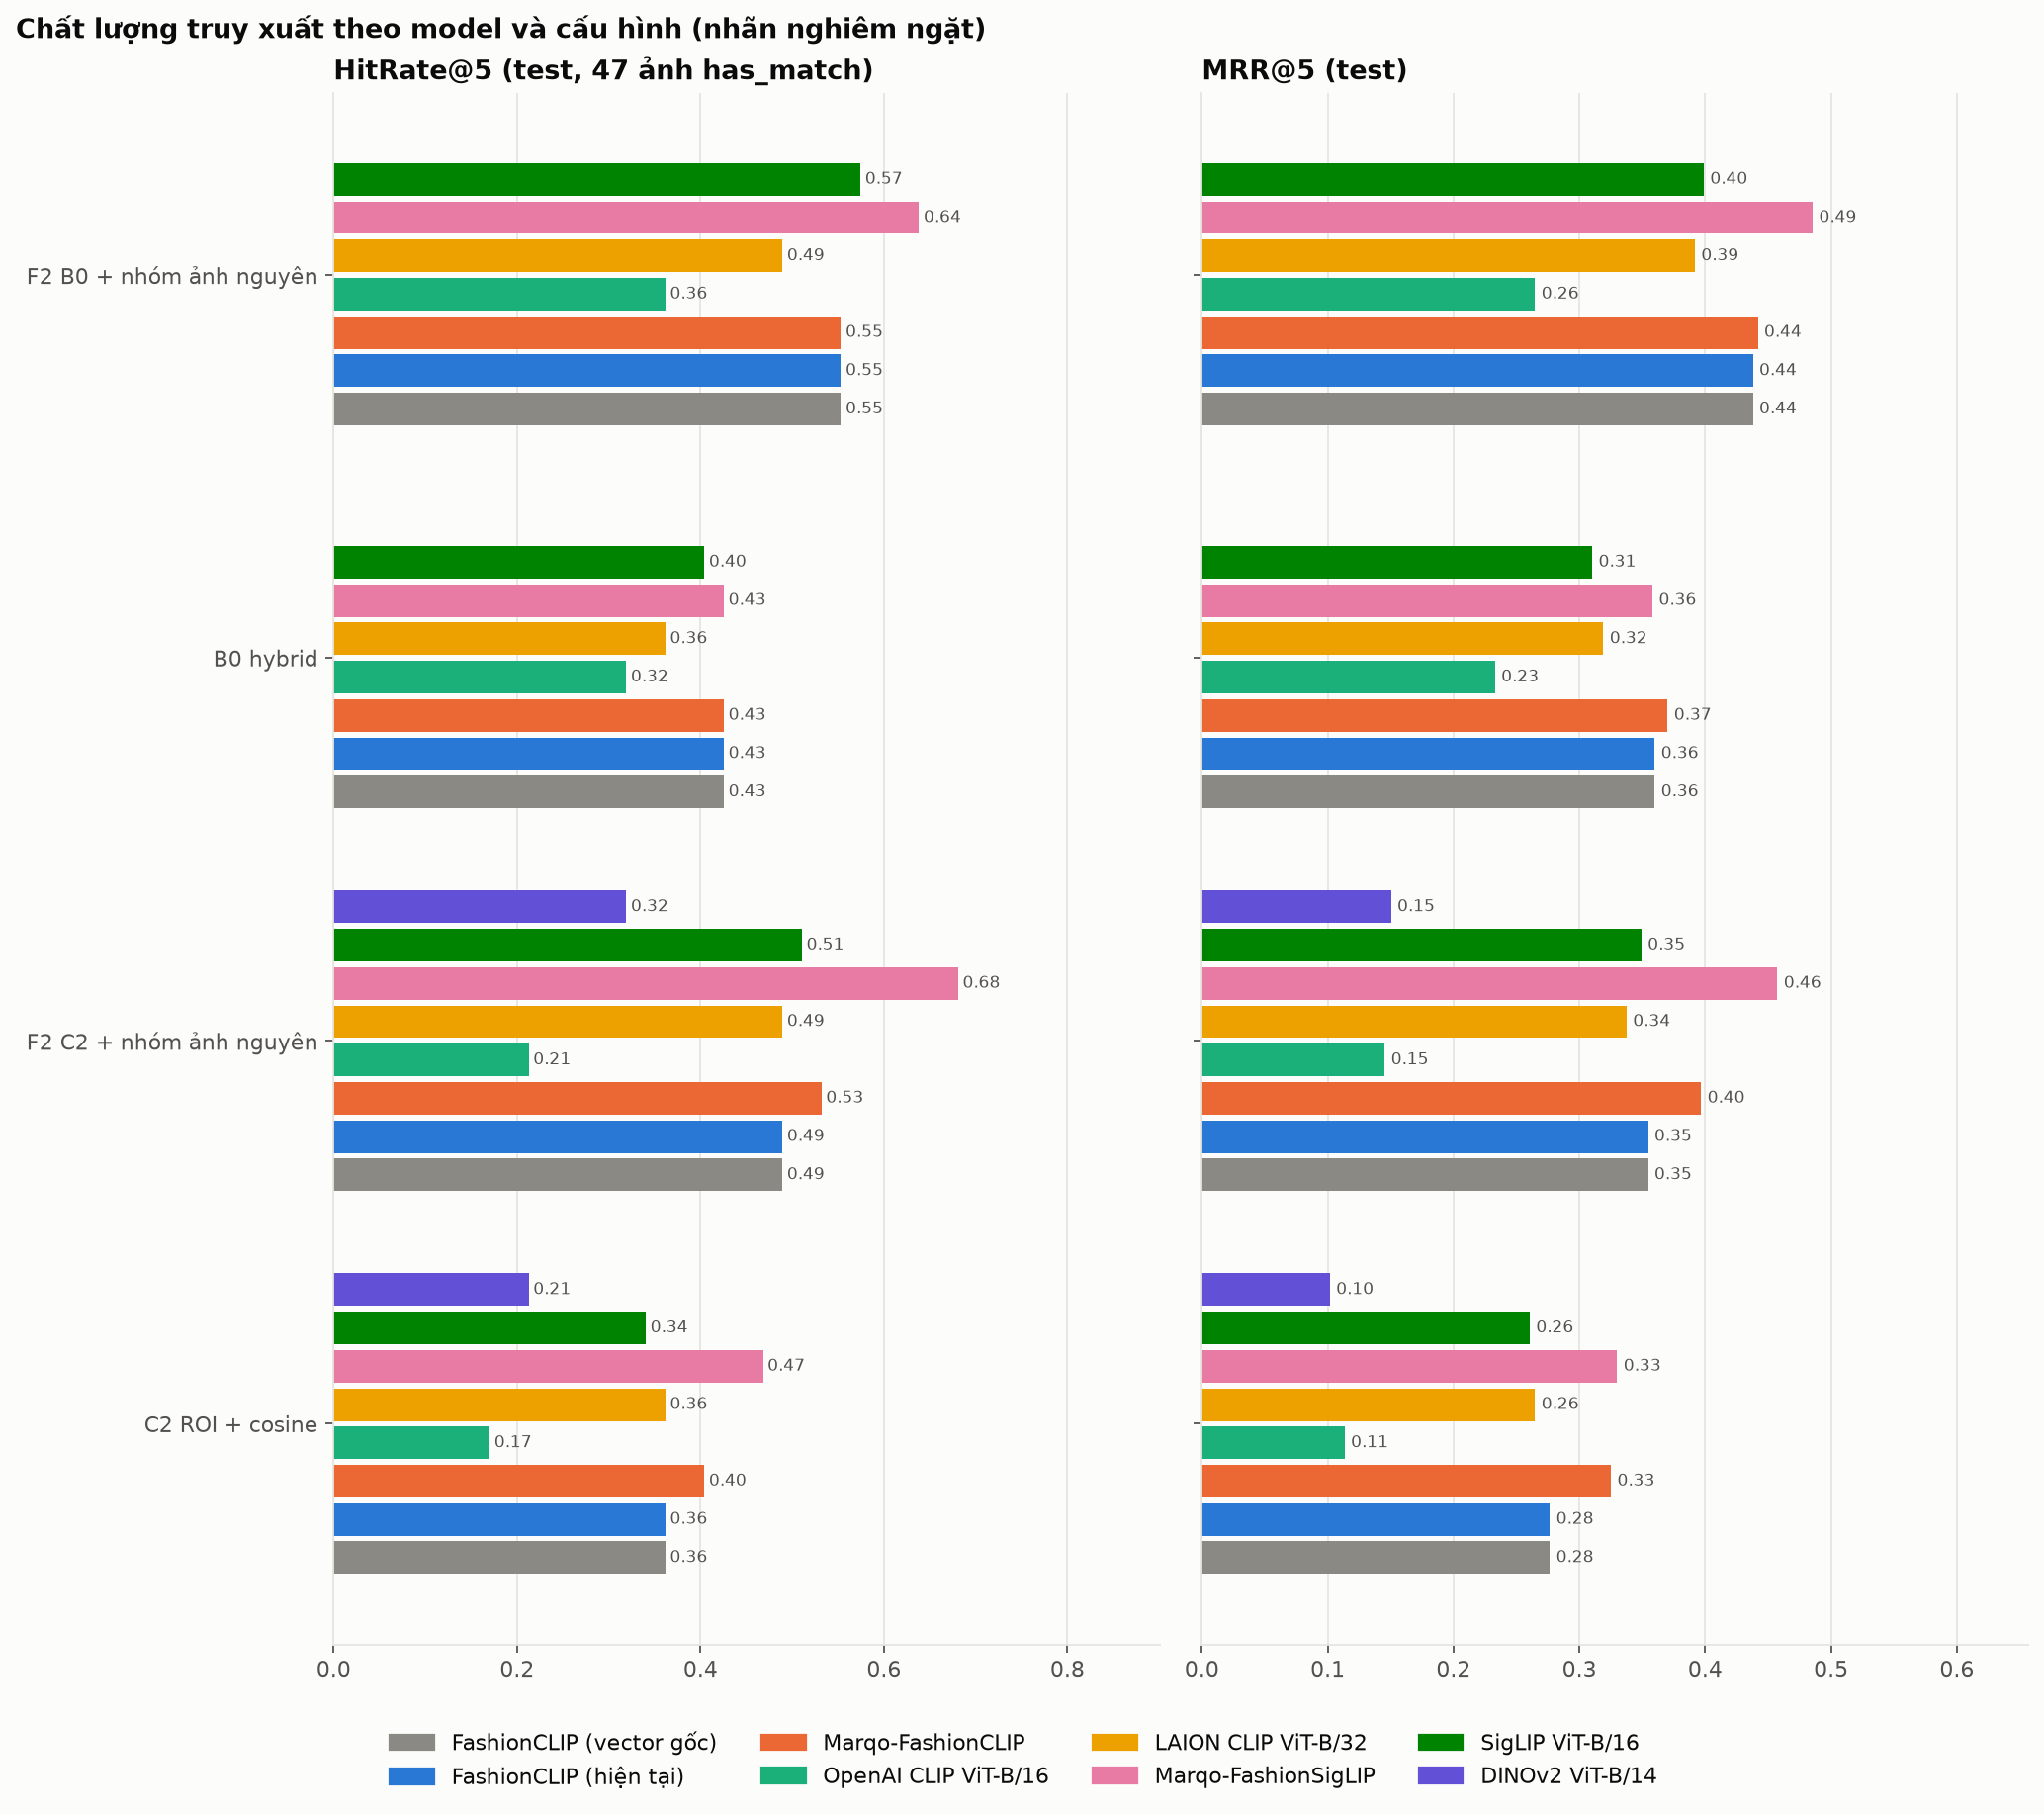

**01_hitrate_mrr_validation.png**

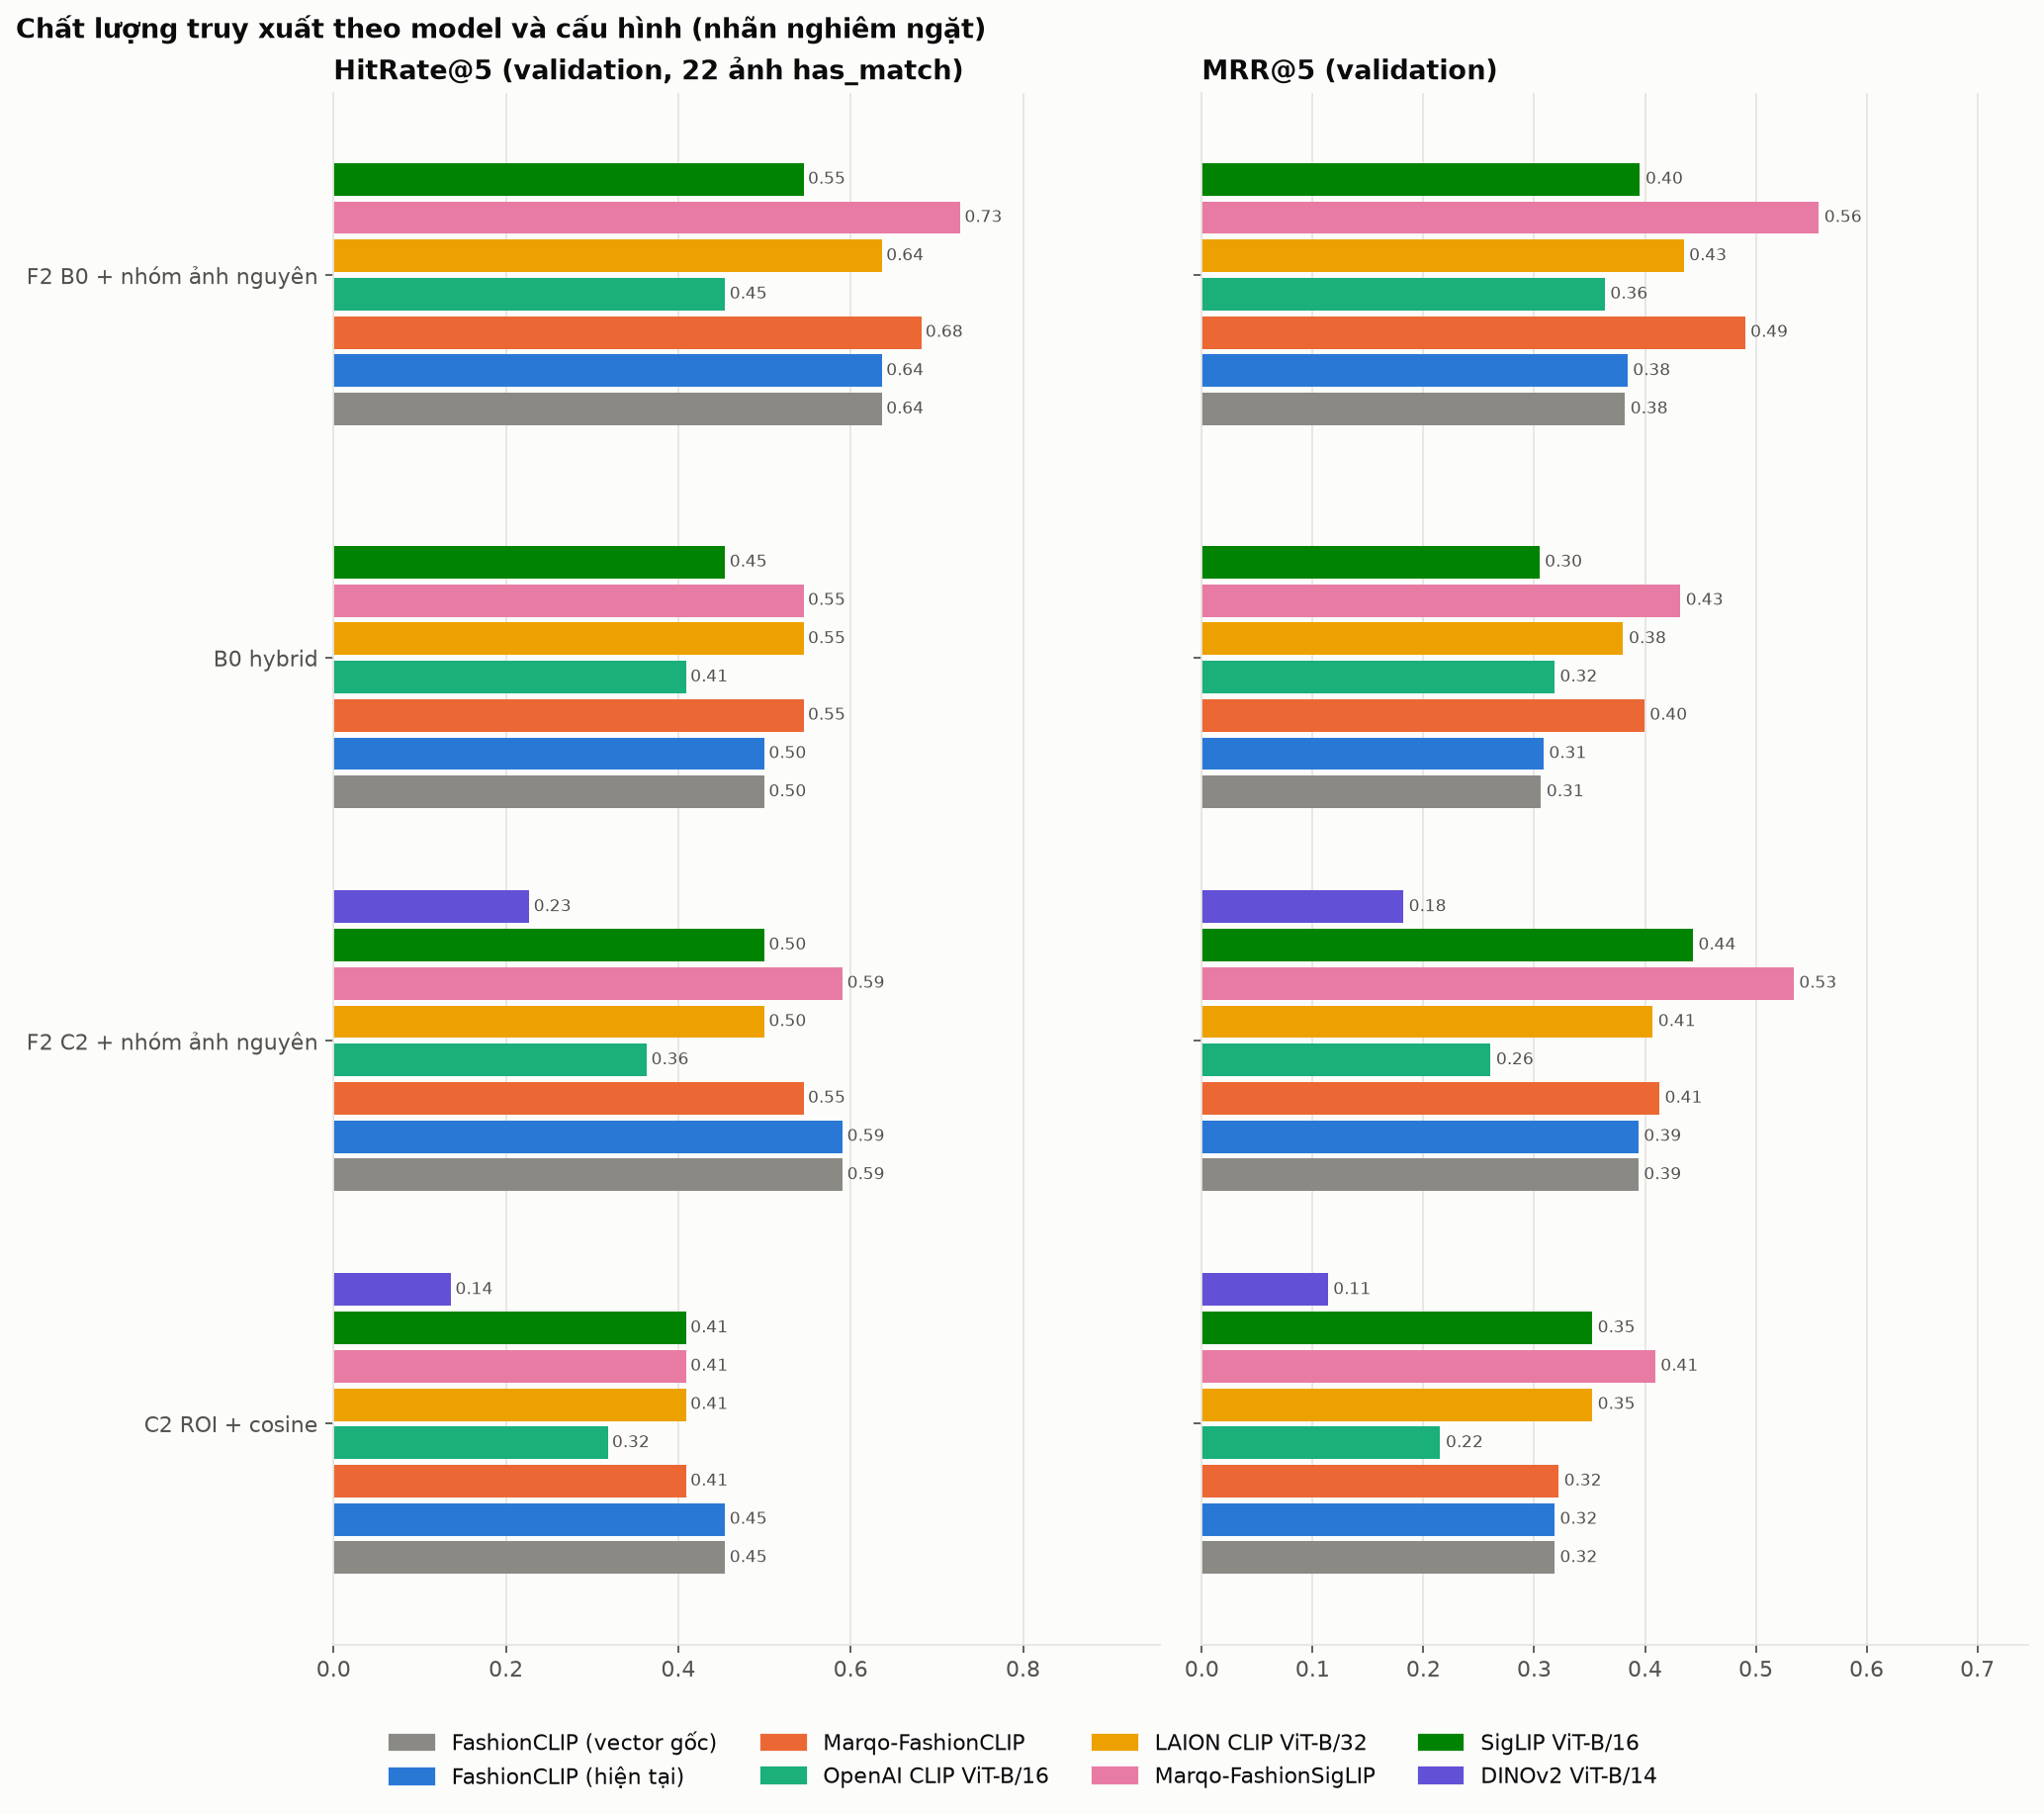

**02_strict_vs_judged_test.png**

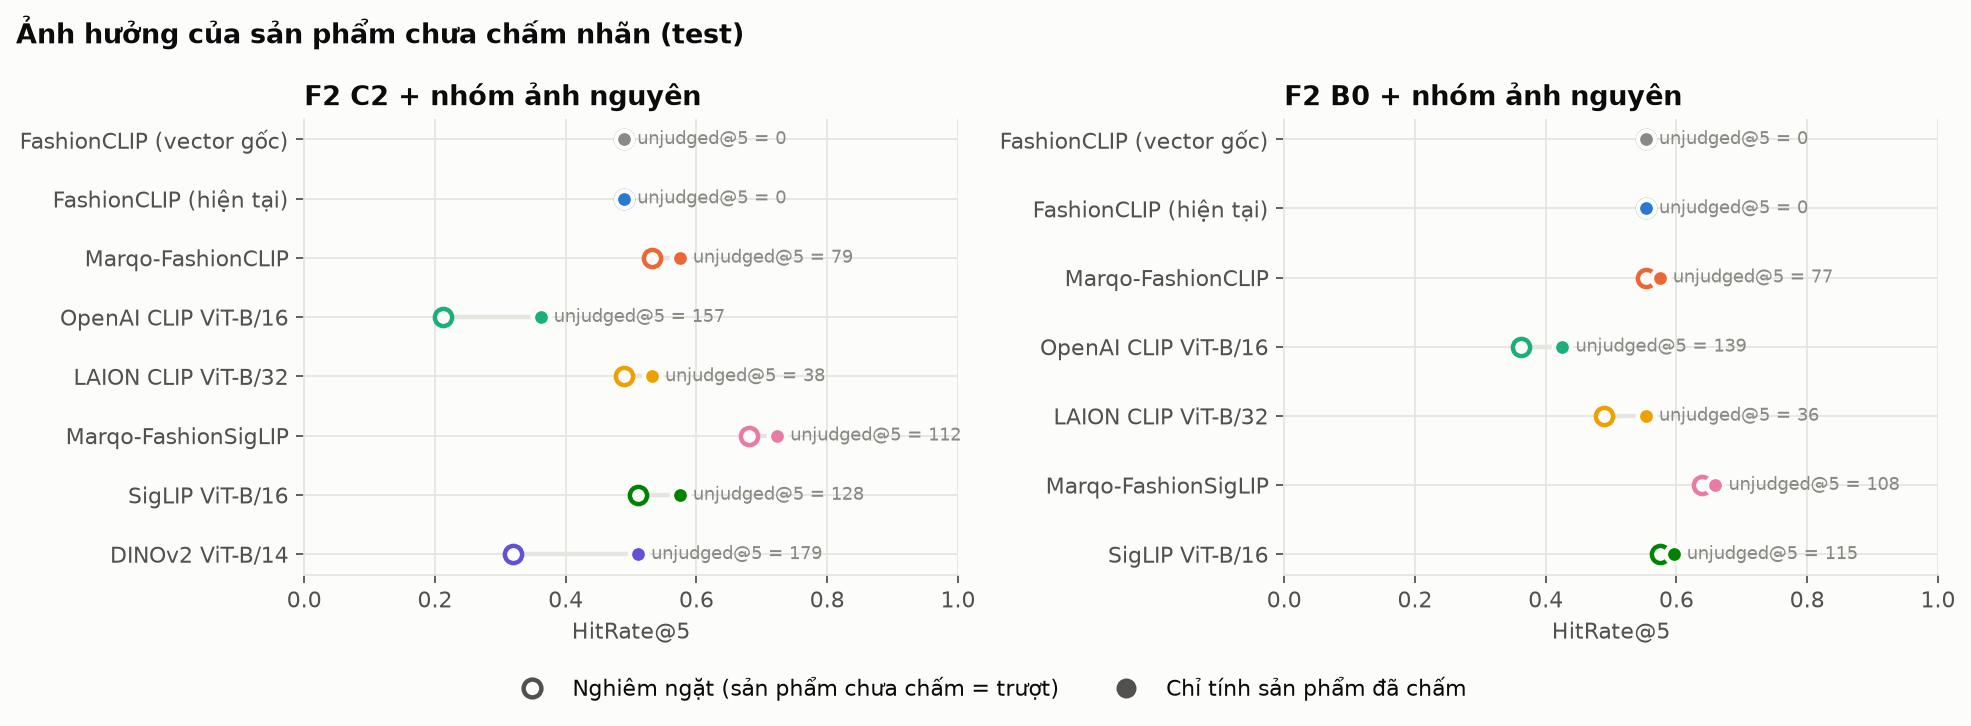

**04_paired_vs_fashionclip_test.png**

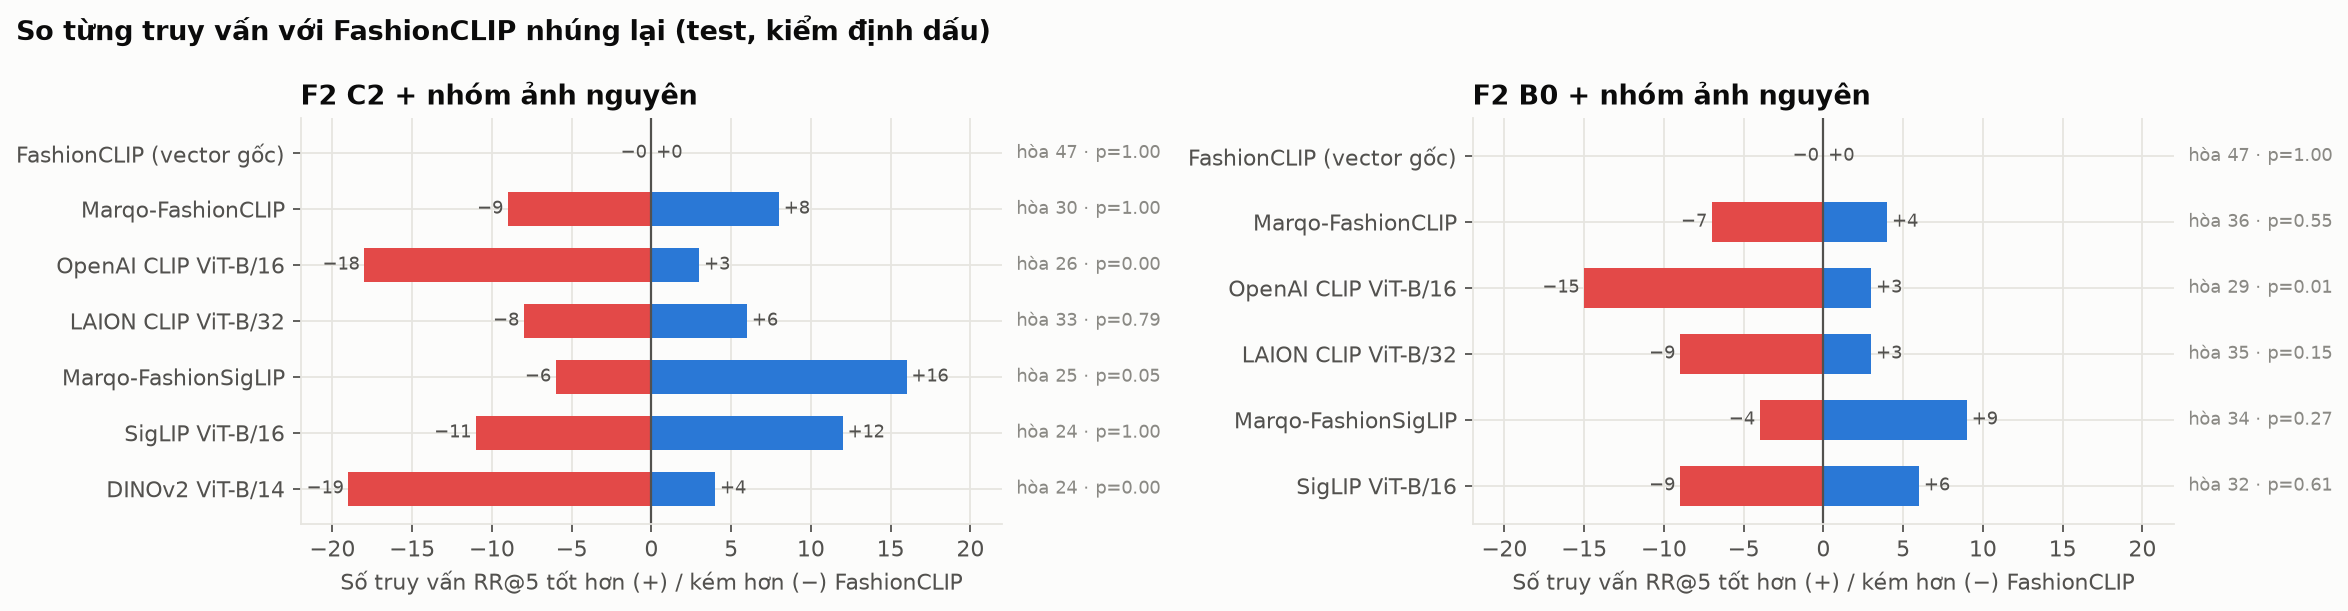

**05_class_heatmap_test_F2_B0_whole.png**

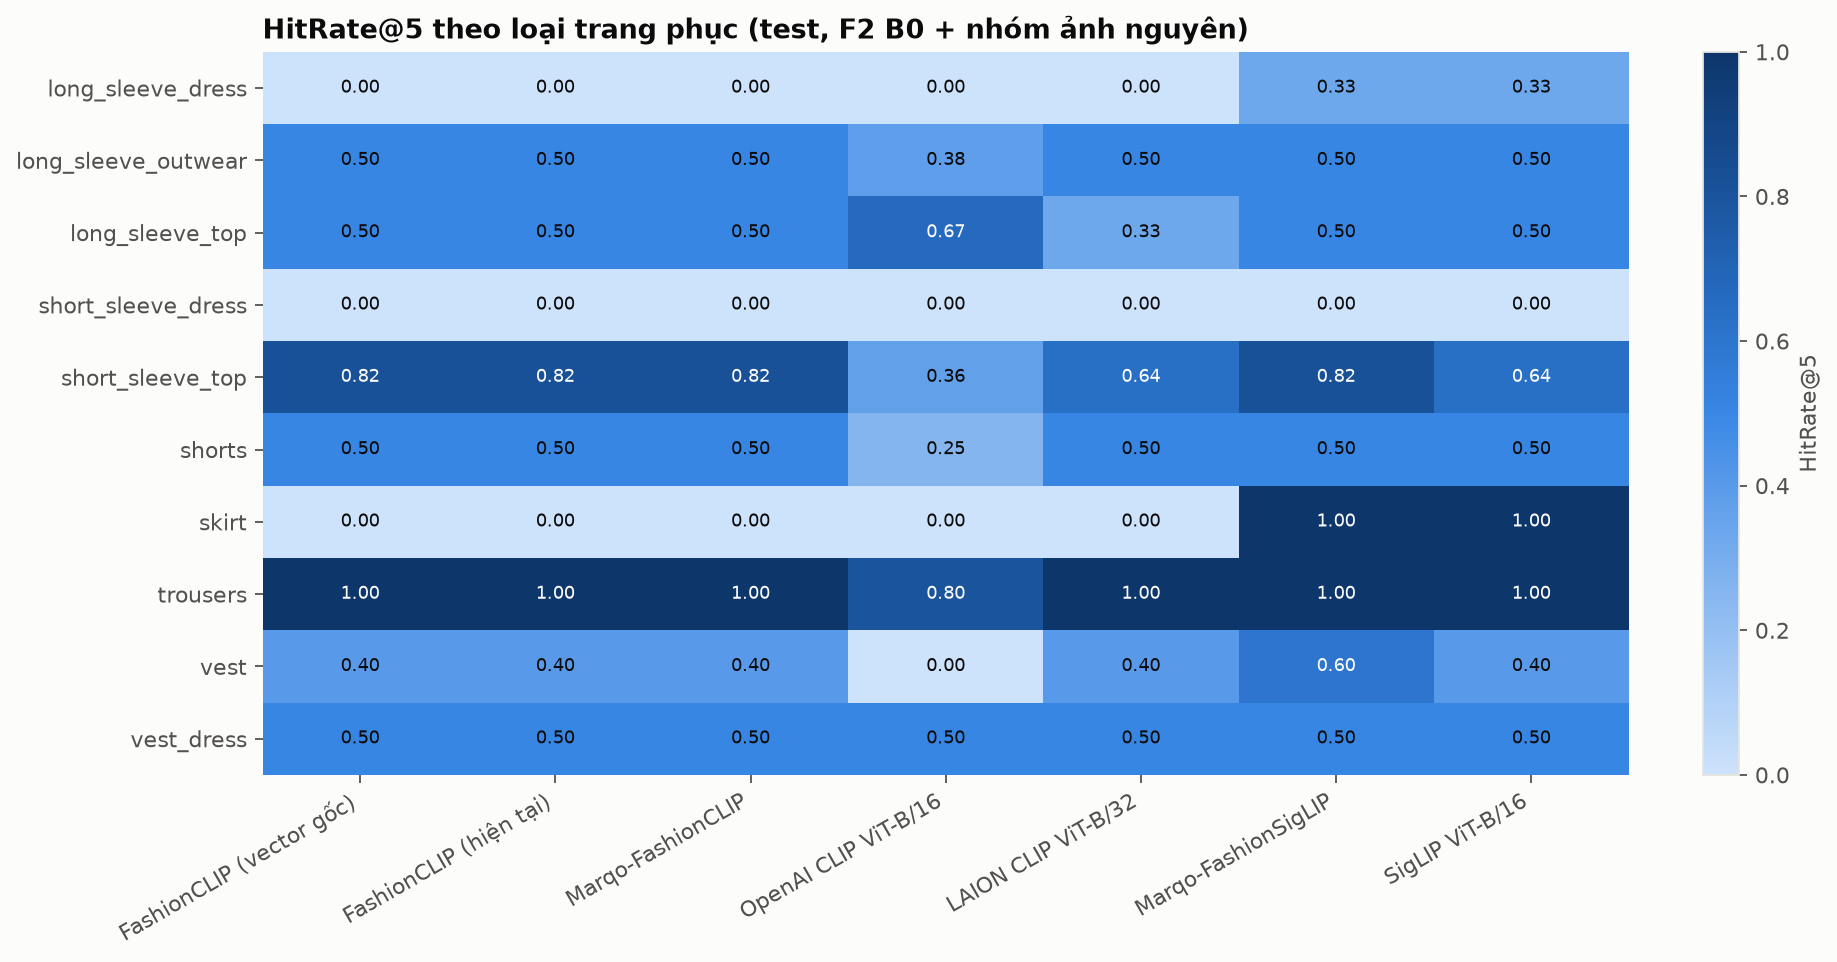

**07_failures_test_F2_B0_whole.png**

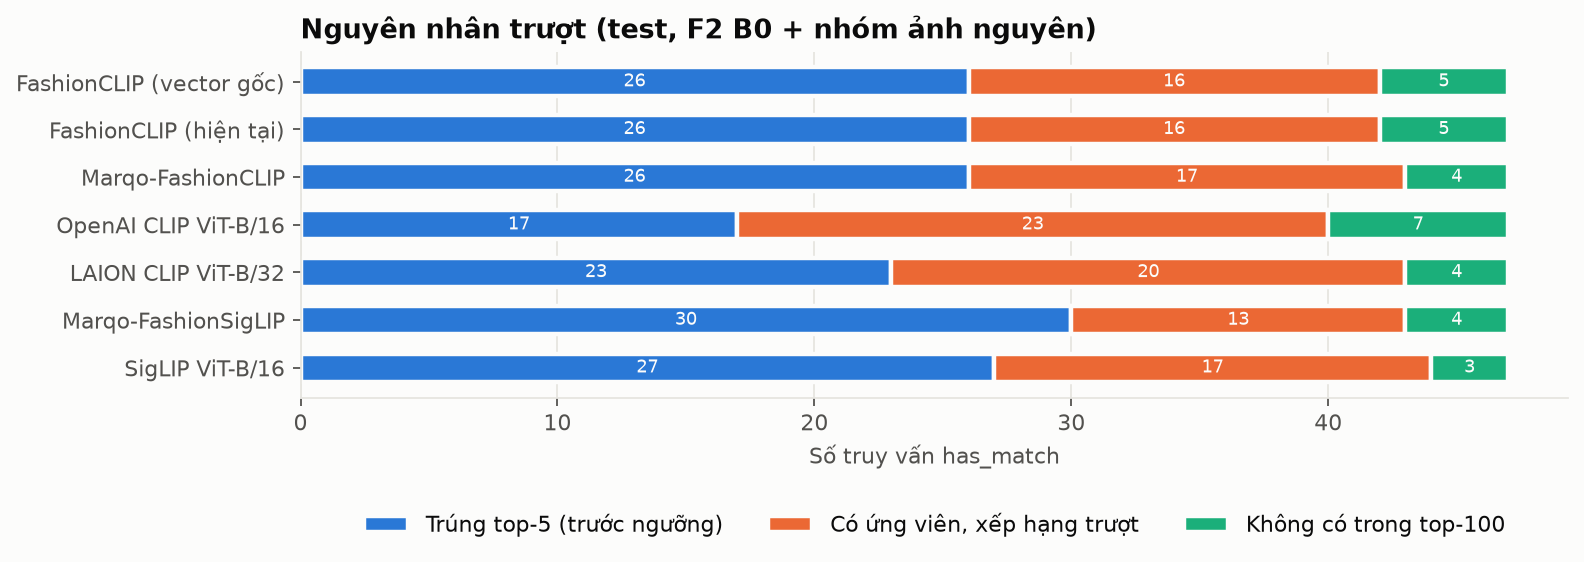

**07_failures_test_F2_C2_whole.png**

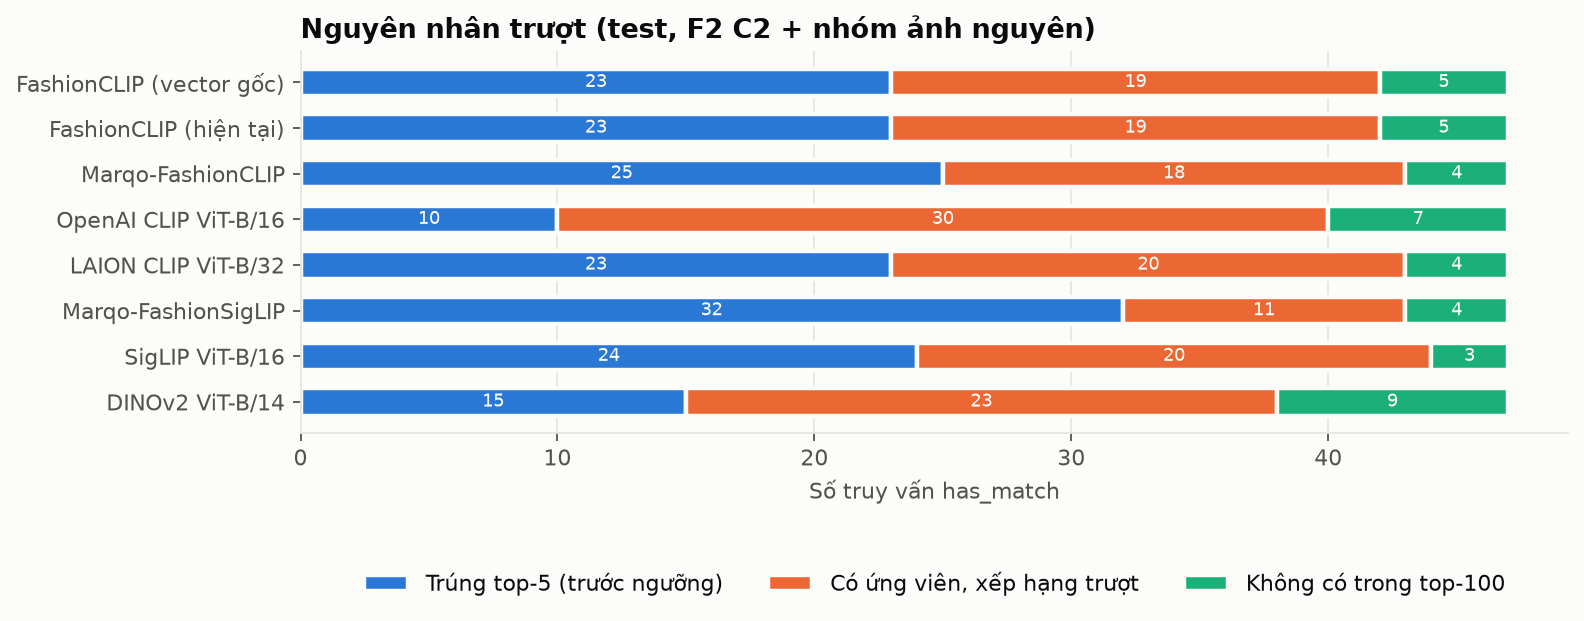

**06_latency_test.png**

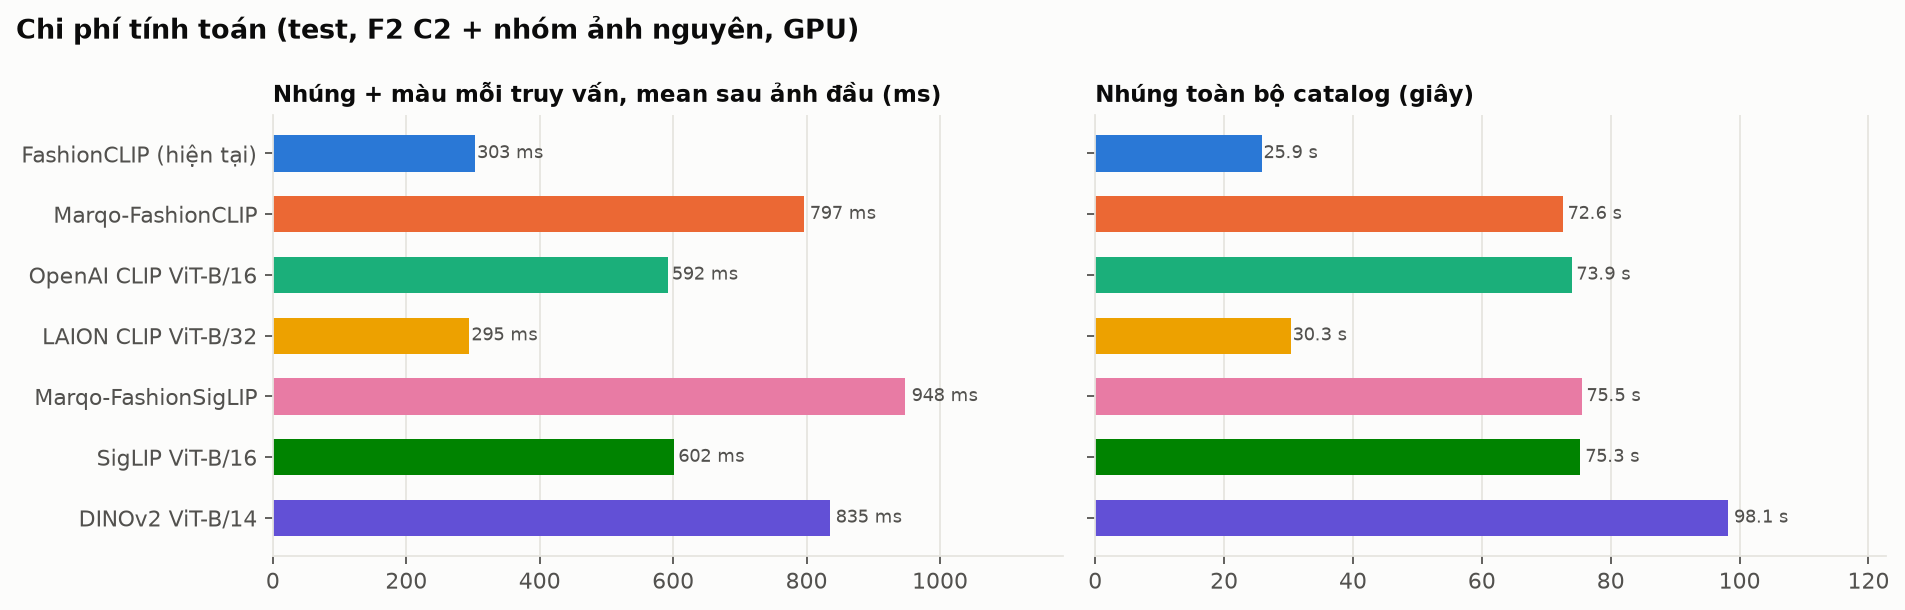

In [6]:
MAIN = ["C2_embedding_only", "F2_C2_whole", "B0_current", "F2_B0_whole"]
figures = [
    plots.config_gain(summary, "test", REPORTS),
    plots.config_gain(summary, "validation", REPORTS),
    plots.hit_mrr(summary, "test", REPORTS, configs=MAIN),
    plots.hit_mrr(summary, "validation", REPORTS, configs=MAIN),
    plots.strict_vs_judged(summary, "test", REPORTS, configs=("F2_C2_whole", "F2_B0_whole")),
    plots.paired(paired, "test", REPORTS, configs=("F2_C2_whole", "F2_B0_whole")),
    plots.class_heatmap(class_breakdown(per_query, "test", "F2_B0_whole"), "test", "F2_B0_whole", REPORTS),
    plots.failures(failure_counts, "test", "F2_B0_whole", REPORTS),
    plots.failures(failure_counts, "test", "F2_C2_whole", REPORTS),
    plots.latency(summary, "test", REPORTS, config="F2_C2_whole"),
]
import matplotlib.pyplot as plt
plt.close("all")
for path in filter(None, figures):
    display(Markdown(f"**{path.name}**"), Image(filename=str(path)))

## 6. So từng truy vấn với FashionCLIP (cấu hình v1)

In [7]:
display(paired[(paired["split"] == "test") & paired["config"].isin(["F2_C2_whole", "F2_B0_whole"])]
        .sort_values(["config", "model"]))

,split,config,model,win,loss,tie,sign_test_p
32,test,F2_B0_whole,clip_b16,3,15,29,0.008
33,test,F2_B0_whole,fashionclip_stored,0,0,47,1.000
34,test,F2_B0_whole,laion_b32,3,9,35,0.146
35,test,F2_B0_whole,marqo_fashionclip,4,7,36,0.549
36,test,F2_B0_whole,marqo_fashionsiglip,9,4,34,0.267
37,test,F2_B0_whole,siglip_b16,6,9,32,0.607
38,test,F2_C2_whole,clip_b16,3,18,26,0.001
39,test,F2_C2_whole,dinov2_base,4,19,24,0.003
40,test,F2_C2_whole,fashionclip_stored,0,0,47,1.000
41,test,F2_C2_whole,laion_b32,6,8,33,0.791


## 7. Tóm tắt tự động (`reports/v1/README.md`)

In [8]:
def row(split, model, config):
    r = summary[(summary["split"] == split) & (summary["model"] == model) & (summary["config"] == config)]
    return r.iloc[0] if not r.empty else None

def cell(split, model, config):
    r = row(split, model, config)
    if r is None:
        return "—"
    return f"{int(r['hit_at_5_n'])}/{int(r['has_match'])} · {r['mrr_at_5']:.3f}"

models = [m for m in summary["model"].unique() if m != STORED]
order = {m: i for i, m in enumerate(["fashionclip", "marqo_fashionclip", "clip_b16", "laion_b32",
                                     "marqo_fashionsiglip", "siglip_b16", "dinov2_base"])}
models.sort(key=lambda m: order.get(m, 99))
lines = ["# Benchmark v1: thêm nhóm kết quả theo ảnh nguyên", "",
         "Tạo bởi `evaluation_new/benchmark_v1.ipynb`. Test 52 ảnh (47 `has_match`, 4 `no_match`), validation 23 ảnh.",
         f"Khóa trên validation lúc {lock['locked_at']}; cấu hình chính đã khóa: **{lock['adopted_main_config']}**.", "",
         "## Định nghĩa", "",
         "- `F1_B0_nodet`: B0; YOLO không trả hộp nào thì tìm bằng ảnh nguyên. Không bao giờ kích hoạt vì YOLO luôn trả ít nhất một hộp (75/75 ảnh).",
         "- `F2_B0_whole` / `F2_C2_whole`: các nhóm theo món của B0 / C2, cộng một nhóm \"ảnh nguyên\" (cosine như A0, qua ngưỡng production 0,70 / 0,60).",
         "- Nhóm người dùng chọn: nhóm YOLO đúng lớp và IoU ≥ 0,5 nếu có, nếu không thì nhóm ảnh nguyên (cùng giả định với v0).",
         "", "## HitRate@5 · MRR@5 trên tập test", "",
         "| Model | C2 | F2_C2_whole | B0 | F2_B0_whole |", "|---|---|---|---|---|"]
for m in models:
    lines.append(f"| {plots.model_label(m)} | " + " | ".join(
        cell("test", m, c) for c in ("C2_embedding_only", "F2_C2_whole", "B0_current", "F2_B0_whole")) + " |")
lines += ["", "## Validation", "", "| Model | C2 | F2_C2_whole | B0 | F2_B0_whole |", "|---|---|---|---|---|"]
for m in models:
    lines.append(f"| {plots.model_label(m)} | " + " | ".join(
        cell("validation", m, c) for c in ("C2_embedding_only", "F2_C2_whole", "B0_current", "F2_B0_whole")) + " |")
fa = summary[(summary["split"] == "test") & summary["config"].isin(["B0_current", "F2_B0_whole"]) & (summary["model"] != STORED)]
lines += ["", "## False acceptance trên 4 ảnh `no_match` (test, sau ngưỡng)", "",
          "| Model | B0 | F2_B0_whole |", "|---|---|---|"]
for m in models:
    b, f = row("test", m, "B0_current"), row("test", m, "F2_B0_whole")
    if b is not None and f is not None:
        lines.append(f"| {plots.model_label(m)} | {int(b['false_acceptance_n'])}/{int(b['no_match'])} | "
                     f"{int(f['false_acceptance_n'])}/{int(f['no_match'])} |")
lines += ["", "## Bảng test đầy đủ", "", plots.to_markdown(test_table), "",
          "## Biểu đồ", ""] + [f"![{p.stem}]({p.name})" for p in filter(None, figures)]
lines += ["", "## Lưu ý", "",
          "- F2 chỉ đổi kết quả ở những ảnh mà YOLO không có nhóm khớp món cần tìm. Ở các ảnh đó B0/C2 vốn tính là trượt, nên trước ngưỡng F2 không bao giờ kém B0/C2. Cái giá phải trả là thêm một nhóm kết quả trên giao diện, thêm khoảng 30 ms nhúng ảnh nguyên, và rủi ro false acceptance trên ảnh không có sản phẩm phù hợp.",
          "- Kết quả giả định người dùng mở nhóm ảnh nguyên khi không thấy món của mình. Giả định này lạc quan giống cách v0 chọn nhóm theo nhãn.",
          "- Ý tưởng xuất phát từ phân tích lỗi trên tập test v0, nên số test v1 chỉ là xác nhận; validation là bằng chứng sạch hơn.",
          "- Nhãn chỉ phủ sản phẩm đã từng chấm, chủ yếu từ FashionCLIP; xem `unjudged_at_5` và `judged_*`. 47 ảnh: chênh 1 ảnh = 0,021 HitRate."]
(REPORTS / "README.md").write_text("\n".join(lines), encoding="utf-8")
display(Markdown("\n".join(lines[:30])))

# Benchmark v1: thêm nhóm kết quả theo ảnh nguyên

Tạo bởi `evaluation_new/benchmark_v1.ipynb`. Test 52 ảnh (47 `has_match`, 4 `no_match`), validation 23 ảnh.
Khóa trên validation lúc 2026-11-24T15:38:21.856791+00:00; cấu hình chính đã khóa: **F2_B0_whole**.

## Định nghĩa

- `F1_B0_nodet`: B0; YOLO không trả hộp nào thì tìm bằng ảnh nguyên. Không bao giờ kích hoạt vì YOLO luôn trả ít nhất một hộp (75/75 ảnh).
- `F2_B0_whole` / `F2_C2_whole`: các nhóm theo món của B0 / C2, cộng một nhóm "ảnh nguyên" (cosine như A0, qua ngưỡng production 0,70 / 0,60).
- Nhóm người dùng chọn: nhóm YOLO đúng lớp và IoU ≥ 0,5 nếu có, nếu không thì nhóm ảnh nguyên (cùng giả định với v0).

## HitRate@5 · MRR@5 trên tập test

| Model | C2 | F2_C2_whole | B0 | F2_B0_whole |
|---|---|---|---|---|
| FashionCLIP (hiện tại) | 17/47 · 0.277 | 23/47 · 0.355 | 20/47 · 0.360 | 26/47 · 0.438 |
| Marqo-FashionCLIP | 19/47 · 0.325 | 25/47 · 0.397 | 20/47 · 0.370 | 26/47 · 0.442 |
| OpenAI CLIP ViT-B/16 | 8/47 · 0.113 | 10/47 · 0.145 | 15/47 · 0.233 | 17/47 · 0.265 |
| LAION CLIP ViT-B/32 | 17/47 · 0.265 | 23/47 · 0.338 | 17/47 · 0.319 | 23/47 · 0.392 |
| Marqo-FashionSigLIP | 22/47 · 0.330 | 32/47 · 0.457 | 20/47 · 0.358 | 30/47 · 0.485 |
| SigLIP ViT-B/16 | 16/47 · 0.261 | 24/47 · 0.349 | 19/47 · 0.310 | 27/47 · 0.399 |
| DINOv2 ViT-B/14 | 10/47 · 0.102 | 15/47 · 0.150 | — | — |

## Validation

| Model | C2 | F2_C2_whole | B0 | F2_B0_whole |
|---|---|---|---|---|
| FashionCLIP (hiện tại) | 10/22 · 0.318 | 13/22 · 0.394 | 11/22 · 0.308 | 14/22 · 0.384 |
| Marqo-FashionCLIP | 9/22 · 0.322 | 12/22 · 0.413 | 12/22 · 0.399 | 15/22 · 0.490 |
| OpenAI CLIP ViT-B/16 | 7/22 · 0.215 | 8/22 · 0.261 | 9/22 · 0.318 | 10/22 · 0.364 |